# Laboratorio dirigido 12 — Analítica de procesos internos
**Caso:** monitoreo de la temperatura de una máquina industrial y priorización de alertas operativas.
**Datos reales:** Numenta Anomaly Benchmark (NAB), serie `machine_temperature_system_failure`: lecturas cada 5 minutos del sensor de temperatura de un componente interno de una máquina industrial grande, del 2 de diciembre de 2013 al 19 de febrero de 2014. La fuente no indica la unidad de medida.
**Pregunta:** ¿qué lecturas y qué días merecen revisión primero, sin acusar una falla a partir de una simple rareza estadística?

> Referencia: Lavin, A. y Ahmad, S. (2015). *Evaluating Real-Time Anomaly Detection Algorithms — The Numenta Anomaly Benchmark.* 14th IEEE International Conference on Machine Learning and Applications.

## Objetivos y teoría
La detección de anomalías identifica observaciones poco habituales según un conjunto de variables. Isolation Forest produce una puntuación de rareza; el umbral se calibra exclusivamente con la línea base. La carta p monitorea la proporción diaria de lecturas en alerta con límites que dependen del número de lecturas de cada día. Una alerta es un motivo para investigar, no una prueba de falla.

Los autores de NAB señalan **ventanas de anomalía** en la serie. Se usan solo como referencia para contrastar las alertas **después** de calibrar el modelo: son ventanas aproximadas y la fuente no explica la causa de cada una.

## Paso 1. Cargar datos abiertos y conservar trazabilidad
Fuente de los datos: https://github.com/numenta/NAB/blob/master/data/realKnownCause/machine_temperature_system_failure.csv . Etiquetas: https://github.com/numenta/NAB/blob/master/labels/combined_windows.json . Licencia del repositorio: MIT (Numenta, 2014-2024).

In [1]:
!pip -q install scikit-learn
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
BASE_URL = "https://raw.githubusercontent.com/numenta/NAB/master/"
URL_DATOS = BASE_URL + "data/realKnownCause/machine_temperature_system_failure.csv"
URL_ETIQ = BASE_URL + "labels/combined_windows.json"
raw = pd.read_csv(URL_DATOS, parse_dates=["timestamp"])
print("Filas originales:", len(raw), "Columnas:", list(raw.columns))
print("Desde", raw.timestamp.min(), "hasta", raw.timestamp.max())
print(raw.head())

Filas originales: 22695 Columnas: ['timestamp', 'value']
Desde 2013-12-02 21:15:00 hasta 2014-02-19 15:25:00
            timestamp      value
0 2013-12-02 21:15:00  73.967322
1 2013-12-02 21:20:00  74.935882
2 2013-12-02 21:25:00  76.124162
3 2013-12-02 21:30:00  78.140707
4 2013-12-02 21:35:00  79.329836


## Paso 2. Reglas de calidad y variables derivadas
Se retiran las marcas de tiempo repetidas (se conserva la primera), se ordena la serie y se trabaja con días completos: del 3 de diciembre de 2013 al 18 de febrero de 2014. Son reglas analíticas declaradas, no verdades de la fuente. Las variables derivadas resumen la última hora (12 lecturas): media, desviación y cambio respecto de hace una hora.

In [2]:
# Marcas de tiempo repetidas: se conserva la primera lectura de cada instante
repetidas = raw.timestamp.duplicated(keep="first")
df = raw.loc[~repetidas].sort_values("timestamp").set_index("timestamp")
# Se comprueba que todas las lecturas están separadas por 5 minutos
fuera_de_paso = int((df.index.to_series().diff().dropna() != pd.Timedelta(minutes=5)).sum())
# Solo días completos: el primer y el último día de la fuente están incompletos
df = df.loc["2013-12-03":"2014-02-18 23:59"].copy()
print("Marcas repetidas:", int(repetidas.sum()), "· lecturas útiles:", len(raw) - int(repetidas.sum()))
print("Lecturas fuera del paso de 5 min:", fuera_de_paso, "· lecturas en días completos:", len(df))
print(df.value.describe().round(2))
print("Lecturas por debajo de 20:", int((df.value < 20).sum()))
# Variables derivadas de la última hora; las 11 primeras lecturas no tienen historia suficiente
feat = pd.DataFrame({"valor": df.value,
                     "media_1h": df.value.rolling(12).mean(),
                     "desv_1h": df.value.rolling(12).std(),
                     "cambio_1h": df.value.diff(12)}).dropna()
print("Lecturas con variables completas:", len(feat))

Marcas repetidas: 12 · lecturas útiles: 22683
Lecturas fuera del paso de 5 min: 0 · lecturas en días completos: 22464
count    22464.00
mean        85.87
std         13.80
min          2.08
25%         83.03
50%         89.33
75%         94.00
max        108.51
Name: value, dtype: float64
Lecturas por debajo de 20: 12
Lecturas con variables completas: 22452


## Paso 3. Separar línea base y periodo de seguimiento
Línea base: 3 al 31 de diciembre de 2013. Seguimiento: 1 de enero al 18 de febrero de 2014. La separación se fija antes de examinar las alertas. Las ventanas de NAB se cargan solo para contrastar los resultados.

In [3]:
CORTE = pd.Timestamp("2014-01-01")
base = feat.index < CORTE
# Ventanas de anomalía señaladas por los autores de NAB (solo referencia para contrastar)
etiquetas = json.load(urllib.request.urlopen(URL_ETIQ))["realKnownCause/machine_temperature_system_failure.csv"]
ventanas = [(pd.Timestamp(a), pd.Timestamp(b)) for a, b in etiquetas]
en_ventana = pd.Series(False, index=feat.index)
for a, b in ventanas:
    en_ventana.loc[a:b] = True
print("Línea base:", int(base.sum()), "lecturas · Seguimiento:", int((~base).sum()), "lecturas")
print("Ventanas de referencia:", [(str(a)[:16], str(b)[:16]) for a, b in ventanas])
assert base.sum() > 5000 and (~base).sum() > 10000

Línea base: 8340 lecturas · Seguimiento: 14112 lecturas
Ventanas de referencia: [('2013-12-10 06:25', '2013-12-12 05:35'), ('2013-12-15 17:50', '2013-12-17 17:00'), ('2014-01-27 14:20', '2014-01-29 13:30'), ('2014-02-07 14:55', '2014-02-09 14:05')]


## Paso 4. Detectar lecturas inusuales
El bosque se ajusta solo con la línea base. Una puntuación mayor significa una lectura más atípica. El percentil 99 de la puntuación base fija la alerta principal. El modelo aprende patrones estadísticos; no conoce la causa física de una lectura.

In [4]:
modelo = IsolationForest(n_estimators=150, max_samples=5000, random_state=2026, n_jobs=-1)
# El modelo aprende lo normal solo con la línea base
modelo.fit(feat.loc[base])
# Puntuación de rareza: mayor valor significa lectura más atípica
feat["score"] = -modelo.score_samples(feat[["valor", "media_1h", "desv_1h", "cambio_1h"]])
# Umbral: percentil 99 de las puntuaciones de la línea base
umbral = feat.loc[base, "score"].quantile(0.99)
feat["alerta"] = feat.score >= umbral
print("Umbral:", round(umbral, 4))
print("Alertas en la línea base:", int(feat.loc[base, "alerta"].sum()))
print("Alertas en el seguimiento:", int(feat.loc[~base, "alerta"].sum()))

Umbral: 0.606
Alertas en la línea base: 84
Alertas en el seguimiento: 495


## Paso 5. Carta p con límites diarios
La proporción base p̄ es el total de alertas base dividido por el total de lecturas base. Cada límite superior usa el número n de lecturas del día. Se muestran todos los días, pero la evaluación de señales fuera de control se hace sobre el seguimiento. Las lecturas contiguas están correlacionadas, de modo que el supuesto binomial es una aproximación.

In [5]:
diario = feat.groupby(feat.index.normalize()).agg(lecturas=("alerta", "size"), alertas=("alerta", "sum"))
pbar = feat.loc[base, "alerta"].mean()
diario["tasa"] = diario.alertas / diario.lecturas
diario["lsc"] = pbar + 3 * np.sqrt(pbar * (1 - pbar) / diario.lecturas)
diario["lic"] = np.maximum(0, pbar - 3 * np.sqrt(pbar * (1 - pbar) / diario.lecturas))
diario["fuera"] = (diario.tasa > diario.lsc) | (diario.tasa < diario.lic)
seguimiento = diario.loc[CORTE:].copy()
print("p̄ =", round(pbar, 5))
print(seguimiento[["lecturas", "alertas", "tasa", "lsc", "fuera"]].query("alertas > 0").to_string())
print("Días fuera de control en el seguimiento:", [str(d)[:10] for d in seguimiento.index[seguimiento.fuera]])
print("Días de la línea base fuera de límites:", int(diario.loc[:CORTE - pd.Timedelta(days=1), "fuera"].sum()), "de", int((diario.index < CORTE).sum()))

p̄ = 0.01007
            lecturas  alertas      tasa       lsc  fuera
timestamp                                               
2014-01-02       288        5  0.017361  0.027724  False
2014-01-05       288        8  0.027778  0.027724   True
2014-01-12       288       13  0.045139  0.027724   True
2014-01-16       288        8  0.027778  0.027724   True
2014-01-24       288       12  0.041667  0.027724   True
2014-01-31       288        1  0.003472  0.027724  False
2014-02-03       288       25  0.086806  0.027724   True
2014-02-07       288        5  0.017361  0.027724  False
2014-02-08       288      246  0.854167  0.027724   True
2014-02-09       288      158  0.548611  0.027724   True
2014-02-13       288        8  0.027778  0.027724   True
2014-02-14       288        6  0.020833  0.027724  False
Días fuera de control en el seguimiento: ['2014-01-05', '2014-01-12', '2014-01-16', '2014-01-24', '2014-02-03', '2014-02-08', '2014-02-09', '2014-02-13']
Días de la línea base fuera de lími

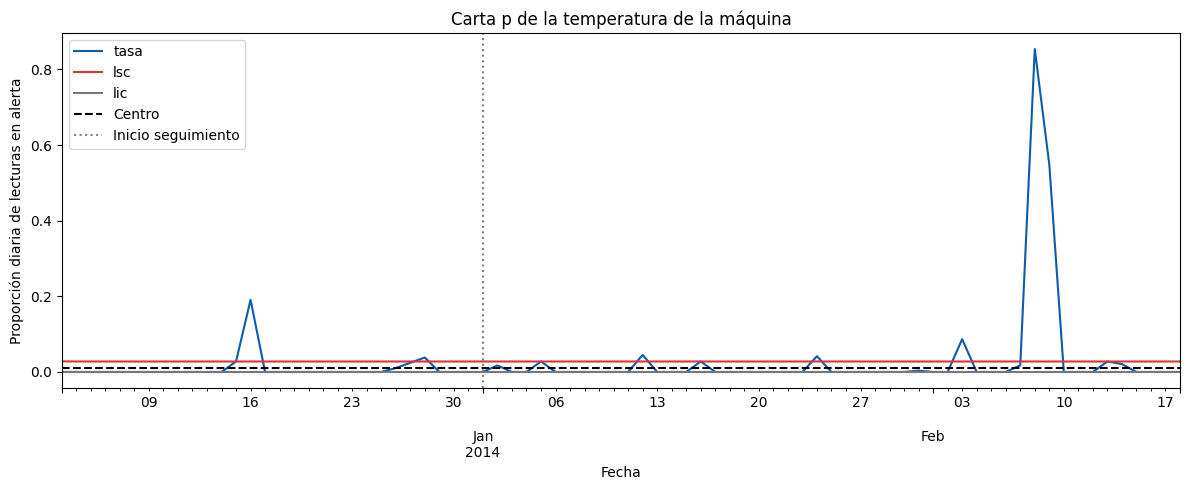

In [6]:
ax = diario[["tasa", "lsc", "lic"]].plot(figsize=(12, 5), color=["#0B5CAD", "#D33", "#777"])
ax.axhline(pbar, color="black", ls="--", label="Centro")
ax.axvline(CORTE, color="gray", ls=":", label="Inicio seguimiento")
ax.set(ylabel="Proporción diaria de lecturas en alerta", xlabel="Fecha", title="Carta p de la temperatura de la máquina")
ax.legend(); plt.tight_layout(); plt.show()

## Paso 6. Convertir alertas en una cola de revisión
Un **episodio** agrupa las alertas separadas por 30 minutos o menos: es la unidad que el equipo revisa. La capacidad de **1 episodio por día** es un **supuesto académico**. La prioridad es la puntuación máxima del episodio. Se calcula la cola y se contrasta con las ventanas de NAB: un episodio coincide con una ventana si se superponen en el tiempo.

In [7]:
CAPACIDAD_DIA = 1
alertas = feat.loc[feat.alerta, ["score"]].reset_index()
# Un episodio nuevo empieza cuando pasan más de 30 minutos desde la alerta anterior
alertas["episodio"] = (alertas.timestamp.diff() > pd.Timedelta(minutes=30)).cumsum()
episodios = alertas.groupby("episodio").agg(inicio=("timestamp", "min"), fin=("timestamp", "max"),
                                            lecturas=("score", "size"), score_max=("score", "max"))
episodios["dia"] = episodios.inicio.dt.normalize()
# Coincidencia con una ventana de referencia: superposición en el tiempo
episodios["en_ventana"] = [any((i <= b) and (f >= a) for a, b in ventanas) for i, f in zip(episodios.inicio, episodios.fin)]
ep = episodios[episodios.inicio >= CORTE].copy()
# Prioridad dentro de cada día por puntuación máxima; se revisan los primeros hasta completar la capacidad
ep["orden_dia"] = ep.groupby("dia").score_max.rank(method="first", ascending=False)
ep["revisable"] = ep.orden_dia <= CAPACIDAD_DIA
print("Episodios en el seguimiento:", len(ep), "· revisables:", int(ep.revisable.sum()), "· en cola:", int((~ep.revisable).sum()))
print("Episodios que coinciden con una ventana:", int(ep.en_ventana.sum()))
print("Lecturas en alerta dentro de ventanas:", int((feat.loc[~base, "alerta"] & en_ventana[~base]).sum()), "de", int(feat.loc[~base, "alerta"].sum()))
display(ep.sort_values("score_max", ascending=False).head(10).round(3))

Episodios en el seguimiento: 17 · revisables: 11 · en cola: 6
Episodios que coinciden con una ventana: 2
Lecturas en alerta dentro de ventanas: 404 de 495


,inicio,fin,lecturas,score_max,dia,en_ventana,orden_dia,revisable
episodio,,,,,,,,
18,2014-02-08 02:40:00,2014-02-09 13:05:00,403,0.793,2014-02-08,True,1.0,True
15,2014-02-03 11:50:00,2014-02-03 13:10:00,17,0.761,2014-02-03,False,1.0,True
12,2014-01-24 12:50:00,2014-01-24 13:45:00,12,0.679,2014-01-24,False,1.0,True
14,2014-02-03 00:10:00,2014-02-03 00:45:00,8,0.660,2014-02-03,False,2.0,False
9,2014-01-12 09:35:00,2014-01-12 10:10:00,8,0.644,2014-01-12,False,1.0,True
19,2014-02-13 19:30:00,2014-02-13 19:45:00,4,0.640,2014-02-13,False,1.0,True
8,2014-01-12 08:25:00,2014-01-12 08:45:00,5,0.640,2014-01-12,False,2.0,False
11,2014-01-16 13:00:00,2014-01-16 13:25:00,6,0.637,2014-01-16,False,1.0,True
7,2014-01-05 17:50:00,2014-01-05 18:25:00,8,0.634,2014-01-05,False,1.0,True


## Paso 7. Sensibilidad del umbral
Compare los percentiles base 98, 99 y 99,5. Para cada uno reporte alertas de seguimiento, episodios, episodios que coinciden con una ventana, días fuera de control y cola con la capacidad de 1 episodio por día. El umbral se calcula siempre en la línea base.

In [8]:
filas = []
for q in [0.98, 0.99, 0.995]:
    corte_q = feat.loc[base, "score"].quantile(q)
    a = feat.score >= corte_q
    pq = a[base].mean()
    n_dia = a.groupby(a.index.normalize()).size()
    k_dia = a.groupby(a.index.normalize()).sum()
    lsc_q = pq + 3 * np.sqrt(pq * (1 - pq) / n_dia)
    fuera_q = int(((k_dia / n_dia > lsc_q) & (n_dia.index >= CORTE)).sum())
    ix = a[a].index.to_series()
    nuevo = (ix.diff() > pd.Timedelta(minutes=30)).cumsum()
    e = pd.DataFrame({"inicio": ix.groupby(nuevo).min(), "fin": ix.groupby(nuevo).max()})
    e = e[e.inicio >= CORTE]
    e["en_ventana"] = [any((i <= b2) and (f >= a2) for a2, b2 in ventanas) for i, f in zip(e.inicio, e.fin)]
    cola = int((e.groupby(e.inicio.dt.normalize()).size() - CAPACIDAD_DIA).clip(lower=0).sum())
    filas.append({"percentil_base": q, "umbral": corte_q, "alertas": int(a[~base].sum()), "episodios": len(e),
                  "en_ventana": int(e.en_ventana.sum()), "dias_fuera": fuera_q, "cola": cola})
sensibilidad = pd.DataFrame(filas)
display(sensibilidad)

,percentil_base,umbral,alertas,episodios,en_ventana,dias_fuera,cola
0,0.980,0.559949,686,31,4,11,15
1,0.990,0.606017,495,17,2,8,6
2,0.995,0.692755,31,3,2,3,0


## Tres retos individuales — diez ítems
Responda cada pregunta con sus propias palabras y con las cifras de su ejecución.

### Pregunta 1.1
Cuantifique las marcas repetidas, los huecos y el rango de la serie, y explique dos causas posibles de las lecturas muy bajas.

**Respuesta:**

- **Marcas repetidas:** Se encontraron 12 de 22 695 filas originales con marca de tiempo duplicada. Los duplicados traían valores distintos entre sí, por lo que conservar la primera lectura es una regla analítica declarada, no una verdad de la fuente.
- **Huecos:** 0. Tras eliminar las repetidas, ninguna lectura queda fuera del paso de 5 minutos. Los días completos (3 dic al 18 feb) tienen exactamente las 22 464 lecturas esperadas (78 días × 288 lecturas/día).
- **Rango de la serie:** La serie original va del 2 dic 2013 21:15 al 19 feb 2014 15:25. En días completos los valores van de 2,08 a 108,51 (media 85,87; mediana 89,33; la fuente no indica la unidad de medida).
- **Lecturas muy bajas:** Hay 12 lecturas por debajo de 20, todas concentradas el 16 dic 2013 entre las 16:35 y las 17:30, con un mínimo de 2,08 a las 17:25. Ese día cae dentro de la primera ventana de referencia de NAB.

Dos causas posibles: (1) **Parada o apagado real del componente** — la serie desciende de forma continua de 25,7 (16:15) hasta 2,1 (17:25) y luego rebota a 32,0 a las 17:35, patrón compatible con enfriamiento y rearranque; (2) **Fallo de medición** — sensor desconectado, descalibrado o problema de transmisión que reporta un valor irreal. Con solo los datos de temperatura no es posible distinguir una causa de la otra; sería necesaria la bitácora de mantenimiento para confirmarlo.

### Pregunta 1.2
Describa dos episodios del top 10 con cifras (inicio, duración, lecturas en alerta y puntuación) y dos explicaciones operativas posibles para cada uno.

**Respuesta:**

(Cifras con umbral p99 = 0,6060; unidad de temperatura no indicada por la fuente)

**Episodio A — mayor prioridad (episodio 18):**
Inicia el 8 feb 2014 a las 02:40 y termina el 9 feb a las 13:05, una duración aproximada de 34,5 horas (2 070 minutos), con 403 lecturas en alerta y puntuación máxima de 0,793. Durante ese período la lectura bajó desde ~93 hasta ~29-35 y al mediodía del 9 feb volvió a ~88-92. Coincide con la ventana de referencia de NAB del 7 al 9 feb.
- *Explicación 1:* Parada programada o paro por avería de la máquina con enfriamiento prolongado y rearranque el 9 feb por la tarde.
- *Explicación 2:* Falla del sistema de calentamiento o del sensor, que dejó la lectura estancada en un nivel bajo de forma sostenida.

**Episodio B (episodio 15):**
Inicia el 3 feb a las 11:50 y termina a las 13:10 (85 minutos), con 17 lecturas en alerta y puntuación máxima de 0,761. Entre las 10:00 y las 11:45 la lectura estaba en ~44-48, luego subió a 68 a las 12:00 y a 93 a las 12:45; el cambio en una hora llega a +50 y la desviación a 18,5. No coincide con ninguna ventana de NAB.
- *Explicación 1:* Arranque posterior a una parada (el episodio vecino del mismo día, 00:10-00:45, muestra una caída abrupta), es decir, un ciclo apagado-encendido que genera una subida brusca de temperatura.
- *Explicación 2:* Intervención de mantenimiento, cambio de set point o reconexión de sensor que provoca una variación repentina no relacionada con una falla real del componente.

### Pregunta 1.3
Identifique los días fuera de control e indique por qué son señales para investigar.

**Respuesta:**

Con p̄ = 0,01007 y n = 288 lecturas por día, el límite superior de control es 0,0277 (equivalente a más de ~7,98 alertas diarias). En el seguimiento se identificaron **8 días fuera de control**:

| Día | Alertas | Tasa |
|---|---|---|
| 5 ene | 8 | 2,8 % |
| 12 ene | 13 | 4,5 % |
| 16 ene | 8 | 2,8 % |
| 24 ene | 12 | 4,2 % |
| 3 feb | 25 | 8,7 % |
| 8 feb | 246 | 85,4 % |
| 9 feb | 158 | 54,9 % |
| 13 feb | 8 | 2,8 % |

Son señales para investigar porque la proporción diaria de lecturas atípicas supera lo que la línea base hacía esperar (~3 alertas por día en promedio). Sin embargo, no constituyen prueba de falla: los días 5 ene, 16 ene y 13 feb superan el límite por apenas una alerta; las lecturas contiguas están correlacionadas, por lo que el supuesto binomial es una aproximación y los límites son optimistas (en la propia línea base 3 de 29 días quedaron fuera); y al evaluar 49 días, algún falso positivo es estadísticamente esperable. Los días 8 y 9 feb son de otra magnitud y coinciden con la ventana de referencia de NAB, lo que justifica una revisión prioritaria.

### Pregunta 1.4
Proponga tres verificaciones externas antes de concluir una falla.

**Respuesta:**

Antes de concluir que existe una falla, propondría tres verificaciones externas:

1. **Bitácora de mantenimiento y de operación:** Revisar órdenes de trabajo, registros de paradas y arranques, y cambios de set point correspondientes al 16 dic, 24 ene, 3 feb y 7-9 feb. Si hubo una intervención planificada o un paro programado en esas fechas, el patrón atípico tendría explicación operativa y no correspondería a una falla no controlada.

2. **Estado del sensor y variables complementarias:** Verificar la calibración o posible reemplazo del sensor durante el período analizado, comparar sus lecturas con las de un sensor redundante si existe, y contrastar con otras señales de la máquina (corriente, vibración, presión, carga). Un valor de 2,1 registrado el 16 dic debe confirmarse contra esas fuentes; un sensor desconectado puede reportar un valor irreal sin que el componente esté dañado.

3. **Registros de producción, alarmas del sistema de control y consulta a operadores:** Revisar alarmas disparadas, tiempo de línea detenida, rechazos o reclamos de producto asociados a esos períodos, y preguntar directamente a los operadores del turno si observaron alguna consecuencia operativa. Una alerta que no generó ningún impacto en producción reduce la probabilidad de que sea una falla real.

### Pregunta 2.1
Compare los tres umbrales con alertas, episodios, días fuera de control y cola.

**Respuesta:**

| Percentil base | Umbral | Alertas seguimiento | Episodios | Episodios en ventana | Días fuera de control | Cola (1 ep/día) |
|---|---|---|---|---|---|---|
| 98 | 0,5599 | 686 | 31 | 4 | 11 | 15 |
| 99 | 0,6060 | 495 | 17 | 2 | 8 | 6 |
| 99,5 | 0,6928 | 31 | 3 | 2 | 3 | 0 |

Subir el percentil reduce todos los indicadores de forma considerable: de 686 a 31 alertas y de 31 a 3 episodios. Con p98 se detectan las dos ventanas del seguimiento (27 ene y 7 feb), pero genera 31 episodios en 16 días, dejando 15 sin revisar. Con p99 solo se toca la ventana del 7 feb y la cola es de 6 episodios. Con p99,5 la cola es cero y también se detecta la ventana del 7 feb, pero se descartan casi todos los episodios cortos. Ningún umbral toca la ventana del 27 ene salvo p98. Cabe recordar que por construcción, el 1 % o 2 % de las lecturas normales siempre se marcarán como alerta, respectivamente.

### Pregunta 2.2
Defienda un umbral bajo 1 revisión por día y declare el costo de oportunidad.

**Respuesta:**

Con capacidad de una revisión por día, defendería el **percentil 99,5 (umbral 0,6928)**: produce 3 episodios en 3 días distintos (3 feb 12:05, puntuación 0,761; 8 feb 16:00, 0,702; 9 feb 11:50, 0,793), cola cero, 3 días fuera de control, y toca la ventana del 7-9 feb. Es la única opción en la que cada episodio puede revisarse el mismo día, lo que mantiene la alerta operativamente creíble para el equipo. Con p99 quedan 6 episodios sin atender y con p98 quedan 15, lo que desborda la capacidad declarada.

**Costo de oportunidad:** se pasa de 17 a 3 episodios, es decir, se dejan de examinar los otros 14. Entre los descartados están el episodio del 24 ene 12:50 (12 lecturas, puntuación 0,679), los del 12 ene, 16 ene y 13 feb, y el aviso previo del 7 feb 07:50 (puntuación 0,633), que fue anterior a la caída más severa del 7-9 feb. También se pierde la única oportunidad de tocar la ventana del 27 ene (detectable solo con p98). Si el equipo ampliara su capacidad a 2 o más revisiones diarias, p99 sería la mejor opción. La elección de p99,5 se tomó por restricción de capacidad, no para maximizar la coincidencia con las ventanas de NAB.

### Pregunta 2.3
Para cada ventana de referencia del seguimiento, calcule cuántas horas antes o después de su inicio apareció el primer episodio y explique por qué esa diferencia no demuestra capacidad de predicción.

**Respuesta:**

(Umbral p99; solo ventanas del seguimiento, es decir, desde el 1 ene 2014)

- **Ventana 27 ene 14:20 → 29 ene 13:30:** Ningún episodio se superpone con esta ventana. El último episodio previo fue el 24 ene a las 12:50 (−73,5 h respecto al inicio de la ventana) y el primer episodio posterior fue el 31 ene a las 10:20 (+92,0 h). Con este umbral, la ventana del 27 ene quedó sin detectar.

- **Ventana 7 feb 14:55 → 9 feb 14:05:** El primer episodio que se superpone comienza el 8 feb a las 02:00, es decir, **11,1 horas después del inicio de la ventana**. Antes hubo un episodio el 7 feb a las 07:50 (−7,1 h), pero terminó antes de que comenzara la ventana y no se superpone con ella.

Esa diferencia no demuestra capacidad de predicción por cuatro razones: (1) las ventanas de NAB son aproximadas y fueron definidas conociendo el evento, por lo que su inicio no corresponde necesariamente al momento real de la anomalía; (2) el modelo detecta cuando el patrón ya cambió (la temperatura venía cayendo desde la mañana del 7 feb: media de ~93 a las 00:00, bajando a ~71 entre las 06:00 y 12:00), no antes de que cambie; (3) solo 2 de los 17 episodios coinciden con alguna ventana, lo que impide estimar tasas de verdadero positivo y falsa alarma de forma confiable; (4) los 15 episodios restantes no se relacionan con ninguna ventana de referencia, por lo que no es posible concluir que el sistema anticipa fallas en general.

### Pregunta 3.1
Repita la carta p con una línea base ampliada del 3 de diciembre al 15 de enero, reentrenando el modelo, e informe cambios.

**Respuesta:**

Con la línea base ampliada (3 dic 2013 al 15 ene 2014, 12 660 lecturas) el cambio respecto a la línea base original es pequeño pero informativo:

- El umbral baja levemente de 0,6060 a 0,5997, y p̄ pasa de 0,01007 a 0,01003; el límite superior de la carta p casi no se mueve (pasa de 0,02772 a 0,02762).
- En el tramo desde el 16 ene hay 501 alertas, contra 469 con la línea base original (+32 alertas adicionales).
- Los días fuera de control desde el 16 ene son los mismos 6 en ambas configuraciones: 16 ene, 24 ene, 3 feb, 8 feb, 9 feb y 13 feb.
- El 5 y 12 ene dejan de evaluarse como seguimiento y pasan a ser parte de la línea base. Con ella aumentan los días base fuera de límites (7 de 44 versus 3 de 29 con la base original), señal de que la línea base ampliada contiene eventos atípicos propios (15-16 dic, 26-28 dic, 5 y 12 ene).

**Conclusión:** las señales principales (3 feb y 8-9 feb) son robustas al cambio de línea base. Sin embargo, incluir días anómalos dentro de la base hace que el modelo aprenda en parte lo atípico como normal, lo que puede reducir su sensibilidad futura. Antes de ampliar la línea base conviene revisar y limpiar los días que ya presentaron alertas dentro de ella.

### Pregunta 3.2
Compare el modelo con las cuatro variables y un modelo que usa solo la lectura (valor): alertas, episodios y coincidencia con las ventanas.

**Respuesta:**

| Modelo | Alertas base | Alertas seguimiento | Episodios | Episodios en ventana | Lecturas alerta en ventana |
|---|---|---|---|---|---|
| 4 variables | 84 | 495 | 17 | 2 | 404 (82 %) |
| Solo valor | 84 | 459 | 4 | 1 | 437 (95 %) |

El modelo con una sola variable (valor) es más corto y concentrado: produce 4 episodios, entre ellos el de 37 horas del 7 al 9 feb (que inicia el 7 feb 22:45, antes que con cuatro variables), y solo 4 días fuera de control (15 ene, 3 feb, 8 feb, 9 feb). El modelo de cuatro variables genera más episodios porque también detecta cambios de forma — subidas o bajadas rápidas, picos de volatilidad en la última hora — aunque el nivel instantáneo sea normal (por ejemplo, el 12 ene la lectura estaba en ~93-97 pero cambió unos 12-18 puntos en una hora). Esos episodios cortos son útiles para exploración, pero la mayoría no coincide con ninguna ventana y no se puede determinar si representan problemas reales.

Ninguno de los dos modelos detecta la ventana del 27 ene. Con capacidad de 1 revisión por día, el modelo solo-valor es más manejable (cola cero con p99,5); con mayor capacidad disponible, el modelo de cuatro variables ofrece señales más tempranas de cambios en la dinámica de la serie.

### Pregunta 3.3
Redacte una recomendación ejecutiva de ocho líneas con cifras, responsable, acción, límite y condición de revisión.

**Respuesta:**

1. **Situación:** De 14 112 lecturas del período de seguimiento (1 ene al 18 feb 2014), 495 (3,5 %) quedaron en alerta y se agrupan en 17 episodios distribuidos en 11 días distintos; 8 días superaron el límite superior de la carta p, y los días 8 y 9 feb concentran 404 de las alertas totales.

2. **Prioridad:** Revisar en primer lugar el episodio del 8-9 feb (34,5 h, puntuación máxima 0,793), luego el del 3 feb 11:50 (puntuación 0,761) y el del 24 ene 12:50 (puntuación 0,679).

3. **Responsable:** Jefe de mantenimiento de la planta (supuesto académico), con apoyo del analista de datos para la interpretación de los scores.

4. **Acción:** Cruzar cada episodio priorizado con la bitácora de mantenimiento, el estado del sensor y los registros de producción antes de emitir cualquier orden correctiva o de parada.

5. **Límite operativo:** Una revisión por día (supuesto académico) con umbral p99,5 (0,6928); bajo esa configuración quedan 3 episodios y cola cero. Con umbral p99 hay 6 episodios sin atender en el horizonte analizado.

6. **Costo de oportunidad:** Se dejan sin revisar 14 episodios cortos, entre ellos el aviso previo del 7 feb 07:50 (puntuación 0,633) y la única oportunidad de acercarse a la ventana del 27 ene (detectable solo con p98).

7. **Condición de revisión del sistema:** Recalibrar el umbral con una línea base limpia cada mes, o antes si p̄ sube por encima del 1,0 % o si la cola supera 2 episodios pendientes por día de forma sostenida.

8. **Advertencia:** Una alerta estadística es un motivo de revisión, no una prueba de falla. Solo la verificación externa mediante bitácora, sensor redundante y registros de producción puede confirmar o descartar una falla real del componente.